# GNN: Forward Pass Verification

Implements `GNNModel` (two-layer GraphSAGE) and `train_gnn`. Verifies correct output shape and no NaNs for all three graph types before any training runs. Training runs are in Tasks 4.4, 4.5, 4.6.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path('..').resolve()))

import json
import numpy as np
import pandas as pd
import torch
from pathlib import Path

import config
from src.models import HARModel, GNNModel, compute_har_features, prepare_har_arrays
from src.train import set_seeds, train_gnn, train_gnn_corr_ablation
from src.graphs import (
    build_correlation_graph, build_sector_graph, make_pyg_data,
    precompute_corr_graphs, load_corr_graphs,
)

In [2]:
# Load all data needed by the GNN verification cells and the HAR scatter comparison
weekly_rv = pd.read_parquet(Path(config.DATA_RAW_DIR) / 'weekly_rv.parquet')
target    = pd.read_parquet(Path(config.DATA_FEATURES_DIR) / 'target.parquet')
splits    = pd.read_parquet(Path(config.DATA_FEATURES_DIR) / 'splits.parquet')
tickers   = target.columns.tolist()

# HAR features and fitted model — used in Plot 5 scatter comparison
rv_1w, rv_4w, rv_13w = compute_har_features(weekly_rv)
X_train, y_train, _, _, _ = prepare_har_arrays(
    rv_1w, rv_4w, rv_13w, target, splits, 'train'
)
har = HARModel()
har.fit(X_train, y_train)

# Reconstruct 3D feature tensor
meta          = json.load(open(Path(config.DATA_FEATURES_DIR) / 'features_meta.json'))
feature_names = meta['feature_names']
feat_df       = pd.read_parquet(Path(config.DATA_FEATURES_DIR) / 'features.parquet')
feat_df['week'] = pd.to_datetime(feat_df['week'])
feat_df = feat_df[feat_df['week'].isin(target.index)].copy()
ticker_order    = {t: i for i, t in enumerate(tickers)}
feat_df['_ord'] = feat_df['ticker'].map(ticker_order)
feat_df = feat_df.sort_values(['week', '_ord']).drop(columns='_ord')

n_weeks  = target.shape[0]
n_stocks = target.shape[1]
n_feats  = len(feature_names)

features_3d = feat_df[feature_names].values.reshape(n_weeks, n_stocks, n_feats)
target_arr  = target.values

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

assert features_3d.shape == (n_weeks, n_stocks, n_feats)
assert target_arr.shape  == (n_weeks, n_stocks)
print(f'features_3d: {features_3d.shape}  target_arr: {target_arr.shape}')
print(f'tickers: {len(tickers)}  n_feats: {n_feats}  device: {device}')
print('HAR model fitted on training data.')

features_3d: (572, 460, 10)  target_arr: (572, 460)
tickers: 460  n_feats: 10  device: cpu
HAR model fitted on training data.


In [3]:
log_returns    = pd.read_parquet(Path(config.DATA_RAW_DIR) / "log_returns.parquet")
sector_history = json.load(open(Path(config.DATA_RAW_DIR) / "sector_history.json"))
granger_df     = pd.read_parquet(Path(config.DATA_GRAPHS_DIR) / "granger_edges.parquet")

granger_edge_index = torch.tensor(
    [granger_df["src"].values, granger_df["dst"].values], dtype=torch.long
)
print(f"log_returns:     {log_returns.shape}")
print(f"Granger edges:   {granger_edge_index.shape[1]:,} directed edges")
print(f"sector_history:  {len(sector_history)} tickers")

log_returns:     (2764, 460)
Granger edges:   0 directed edges
sector_history:  460 tickers


In [4]:
# Precompute correlation edge graphs for all splits and thresholds.
# Saves 9 parquet files to data/graphs/corr_edges/ (3 thresholds x 3 splits).
# First run: ~90 seconds total. Subsequent runs: instant (files already exist).
precompute_corr_graphs(log_returns=log_returns, splits=splits)

  train/t0p3: 417 weeks ... 

/Users/shubhankar/Documents/Codex/2026-10-16/https-github-com-waderylan-sp500-gnn/work/sp500-gnn/src/graphs.py:187: UserWarning: build_correlation_graph: fewer than requested rows available — correlation estimated on a shorter window (expected at dataset start).
  ei = build_correlation_graph(log_returns, friday, lookback, threshold)


47,944,626 edges saved
  train/t0p5: 417 weeks ... 

/Users/shubhankar/Documents/Codex/2026-10-16/https-github-com-waderylan-sp500-gnn/work/sp500-gnn/src/graphs.py:187: UserWarning: build_correlation_graph: fewer than requested rows available — correlation estimated on a shorter window (expected at dataset start).
  ei = build_correlation_graph(log_returns, friday, lookback, threshold)


16,937,804 edges saved
  train/t0p7: 417 weeks ... 

/Users/shubhankar/Documents/Codex/2026-10-16/https-github-com-waderylan-sp500-gnn/work/sp500-gnn/src/graphs.py:187: UserWarning: build_correlation_graph: fewer than requested rows available — correlation estimated on a shorter window (expected at dataset start).
  ei = build_correlation_graph(log_returns, friday, lookback, threshold)


2,514,274 edges saved
  val/t0p3: 52 weeks ... 7,361,104 edges saved
  val/t0p5: 52 weeks ... 2,342,826 edges saved
  val/t0p7: 52 weeks ... 176,396 edges saved
  test/t0p3: 103 weeks ... 7,298,222 edges saved
  test/t0p5: 103 weeks ... 1,333,244 edges saved
  test/t0p7: 103 weeks ... 137,676 edges saved
precompute_corr_graphs: done.


In [5]:
# Instantiate GNNModel and print architecture
set_seeds()
gnn_test = GNNModel(in_channels=n_feats).to(device)
print(gnn_test)
print(f"\nTrainable parameters: {sum(p.numel() for p in gnn_test.parameters()):,}")

GNNModel(
  (conv1): SAGEConv(10, 256, aggr=mean)
  (conv2): SAGEConv(256, 256, aggr=mean)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=1, bias=True)
)

Trainable parameters: 136,961


In [6]:
# Build edge indices for one mid-train sample week
sample_pos  = 200
sample_week = target.index[sample_pos]
print(f"Sample week: {sample_week.date()}  (train position {sample_pos})")

corr_edge_index   = build_correlation_graph(
    log_returns, sample_week, config.CORR_LOOKBACK_DAYS, config.CORR_THRESHOLD
)
sector_edge_index = build_sector_graph(tickers, sample_week.year, sector_history)
# granger_edge_index is static — loaded above, same tensor for all time steps

print(f"\nEdge counts at {sample_week.date()}:")
print(f"  Correlation (θ={config.CORR_THRESHOLD}):  {corr_edge_index.shape[1]:>6,}")
print(f"  Sector ({sample_week.year}):                {sector_edge_index.shape[1]:>6,}")
print(f"  Granger (static):              {granger_edge_index.shape[1]:>6,}")

Sample week: 2018-11-05  (train position 200)

Edge counts at 2018-11-05:
  Correlation (θ=0.3):  91,026
  Sector (2018):                24,134
  Granger (static):                   0


In [7]:
# Forward pass — shape and NaN verification on all three graph types
features_t = torch.tensor(features_3d[sample_pos], dtype=torch.float32).to(device)
target_t   = torch.tensor(target_arr[sample_pos],   dtype=torch.float32).to(device)

gnn_test.eval()
with torch.no_grad():
    out_corr    = gnn_test(features_t, corr_edge_index.to(device))
    out_sector  = gnn_test(features_t, sector_edge_index.to(device))
    out_granger = gnn_test(features_t, granger_edge_index.to(device))

print("Forward pass results:")
for name, out in [("Correlation", out_corr), ("Sector", out_sector), ("Granger", out_granger)]:
    print(f"  {name:12s}  shape={tuple(out.shape)}  NaNs={out.isnan().sum().item()}"
          f"  min={out.min().item():+.4f}  max={out.max().item():+.4f}")

assert not out_corr.isnan().any(),    "NaN in Correlation output"
assert not out_sector.isnan().any(),  "NaN in Sector output"
assert not out_granger.isnan().any(), "NaN in Granger output"
print("\nAll shape and NaN assertions passed.")

Forward pass results:
  Correlation   shape=(460,)  NaNs=0  min=-0.3509  max=+0.0343
  Sector        shape=(460,)  NaNs=0  min=-0.3174  max=+0.0085
  Granger       shape=(460,)  NaNs=0  min=-0.2083  max=+0.1066

All shape and NaN assertions passed.


/Users/shubhankar/Documents/Codex/2026-10-16/https-github-com-waderylan-sp500-gnn/work/sp500-gnn/src/models.py:289: UserWarning: GNNModel.forward: input features contain NaN values. Imputing with 0 (z-score mean). Expected during warm-up weeks.
  warnings.warn(


### Plot 1: Output distributions at random initialization

All three variants operating on the same feature vector and same week.
At random init the predictions should be near zero with similar spread.
Red dashed line = mean actual RV for this week (the scale target).

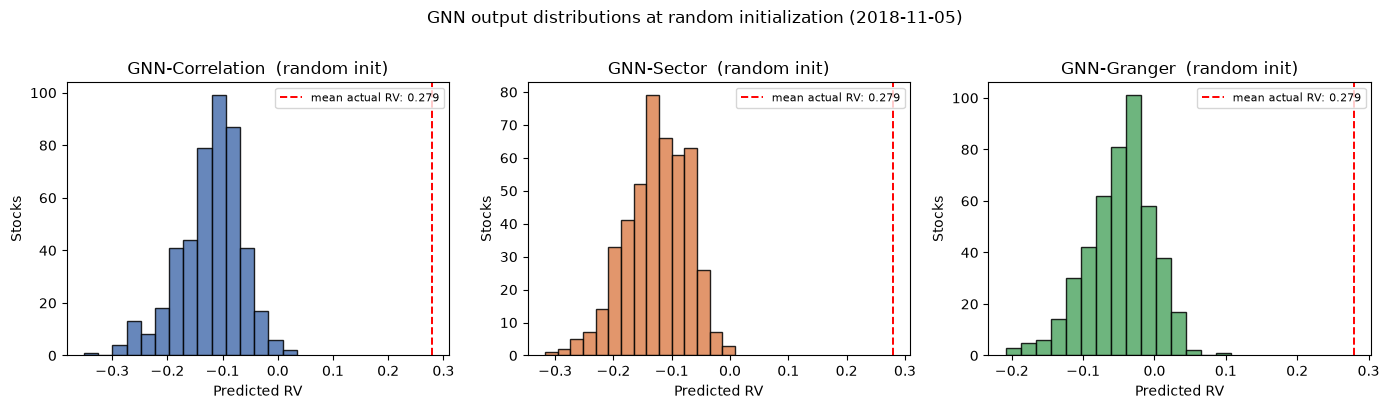

In [8]:
import matplotlib.pyplot as plt

actual_rv    = target_t.cpu().numpy()
mean_actual  = actual_rv.mean()
graph_data   = [
    ("Correlation", out_corr,    "#4C72B0"),
    ("Sector",      out_sector,  "#DD8452"),
    ("Granger",     out_granger, "#55A868"),
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, out, color) in zip(axes, graph_data):
    vals = out.cpu().numpy()
    ax.hist(vals, bins=15, color=color, edgecolor="k", alpha=0.85)
    ax.axvline(mean_actual, color="red", linestyle="--", linewidth=1.4,
               label=f"mean actual RV: {mean_actual:.3f}")
    ax.set_title(f"GNN-{name}  (random init)")
    ax.set_xlabel("Predicted RV")
    ax.set_ylabel("Stocks")
    ax.legend(fontsize=8)

plt.suptitle(f"GNN output distributions at random initialization ({sample_week.date()})", y=1.01)
plt.tight_layout()
plt.show()

### Plot 2: Edge counts at three characteristic dates

Shows how the correlation graph density shifts across market regimes.
Sector and Granger counts are constant (same bars at every date).

calm     (2017-06-30):  corr=38,202  sector=24,134  granger=0
covid    (2020-03-13):  corr=193,246  sector=23,334  granger=0
recent   (2023-06-30):  corr=148,168  sector=23,334  granger=0


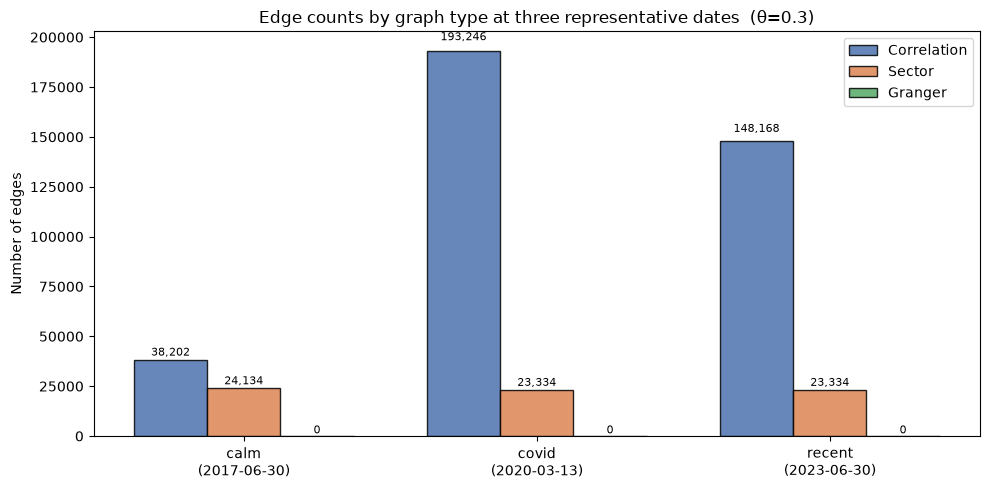

In [9]:
sample_dates = {k: pd.Timestamp(v) for k, v in config.CORR_SAMPLE_DATES.items()}

edge_counts = {}
for label, date in sample_dates.items():
    ei = build_correlation_graph(log_returns, date, config.CORR_LOOKBACK_DAYS, config.CORR_THRESHOLD)
    se = build_sector_graph(tickers, date.year, sector_history)
    edge_counts[label] = {
        "Correlation": ei.shape[1],
        "Sector":      se.shape[1],
        "Granger":     granger_edge_index.shape[1],
    }
    print(f"{label:8s} ({date.date()}):  corr={ei.shape[1]:,}  "
          f"sector={se.shape[1]:,}  granger={granger_edge_index.shape[1]:,}")

labels      = list(sample_dates.keys())
graph_types = ["Correlation", "Sector", "Granger"]
colors      = ["#4C72B0", "#DD8452", "#55A868"]
x           = np.arange(len(labels))
width       = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
for i, (gtype, color) in enumerate(zip(graph_types, colors)):
    counts = [edge_counts[lbl][gtype] for lbl in labels]
    bars   = ax.bar(x + i * width, counts, width, label=gtype, color=color,
                    edgecolor="k", alpha=0.85)
    for bar, count in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 1.02,
                f"{count:,}", ha="center", va="bottom", fontsize=8)

ax.set_xticks(x + width)
ax.set_xticklabels([f"{lbl}\n({sample_dates[lbl].date()})" for lbl in labels])
ax.set_ylabel("Number of edges")
ax.set_title(f"Edge counts by graph type at three representative dates  (θ={config.CORR_THRESHOLD})")
ax.legend()
plt.tight_layout()
plt.show()

### Plot 3: Correlation graph density over training period

30 evenly spaced training weeks. The March 2020 COVID spike should be clearly
visible: when stocks crash together, pairwise correlations surge and the graph
becomes much denser. This is the key motivation for using a dynamic graph.

/var/folders/4n/9vhf3yqn3pj0dt94ktyqrq080000gn/T/ipykernel_36998/914606209.py:11: UserWarning: build_correlation_graph: fewer than requested rows available — correlation estimated on a shorter window (expected at dataset start).
  ei = build_correlation_graph(log_returns, week, config.CORR_LOOKBACK_DAYS, config.CORR_THRESHOLD)


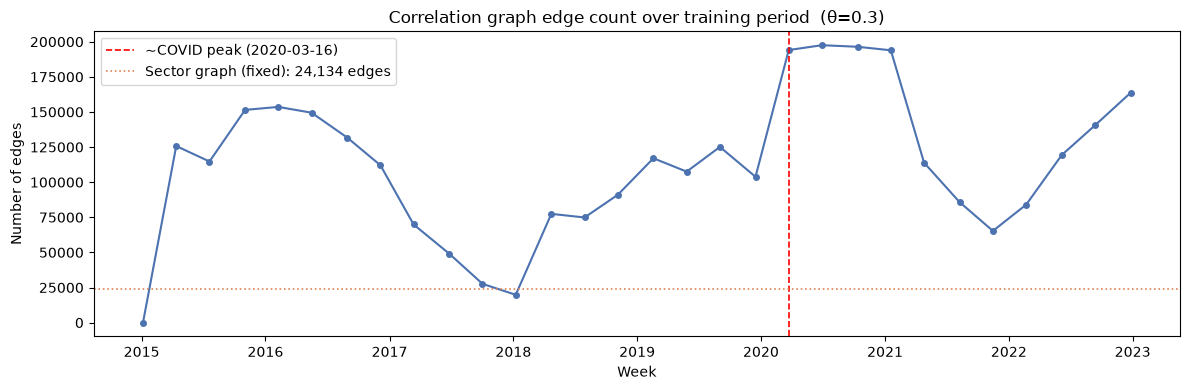

Min edges: 0   Max edges: 197,522   Ratio: 197522.0x


In [10]:
train_weeks_sorted = (
    splits.loc[splits["split"] == "train", "week"]
    .sort_values()
    .reset_index(drop=True)
)
sample_indices = np.linspace(0, len(train_weeks_sorted) - 1, 30, dtype=int)
sampled_weeks  = train_weeks_sorted.iloc[sample_indices]

corr_edge_counts = []
for week in sampled_weeks:
    ei = build_correlation_graph(log_returns, week, config.CORR_LOOKBACK_DAYS, config.CORR_THRESHOLD)
    corr_edge_counts.append(ei.shape[1])

covid_approx = pd.Timestamp("2020-03-16")
closest_covid_i = int(np.argmin(np.abs(sampled_weeks.values - np.datetime64(covid_approx))))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(pd.to_datetime(sampled_weeks.values), corr_edge_counts,
        marker="o", markersize=4, linewidth=1.5, color="#4C72B0")
ax.axvline(pd.to_datetime(sampled_weeks.values[closest_covid_i]),
           color="red", linestyle="--", linewidth=1.2, label="~COVID peak (2020-03-16)")
ax.axhline(sector_edge_index.shape[1], color="#DD8452", linestyle=":",
           linewidth=1.2, label=f"Sector graph (fixed): {sector_edge_index.shape[1]:,} edges")
ax.set_xlabel("Week")
ax.set_ylabel("Number of edges")
ax.set_title(f"Correlation graph edge count over training period  (θ={config.CORR_THRESHOLD})")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Min edges: {min(corr_edge_counts):,}   Max edges: {max(corr_edge_counts):,}"
      f"   Ratio: {max(corr_edge_counts) / max(1, min(corr_edge_counts)):.1f}x")

### Plot 4: Granger directionality verification

Repeats the 3.4 check on the actual `GNNModel` class (not a toy graph).
Every bar must be non-zero: if `SAGEConv` were symmetrizing edges internally,
reversing them would produce identical outputs and all bars would be zero.

Directionality probe edges: synthetic fallback
Directionality confirmed.
  Max  |diff|: 0.1118
  Mean |diff|: 0.0005
  Stocks with diff > 0: 2 / 460


/Users/shubhankar/Documents/Codex/2026-10-16/https-github-com-waderylan-sp500-gnn/work/sp500-gnn/src/models.py:289: UserWarning: GNNModel.forward: input features contain NaN values. Imputing with 0 (z-score mean). Expected during warm-up weeks.
  warnings.warn(


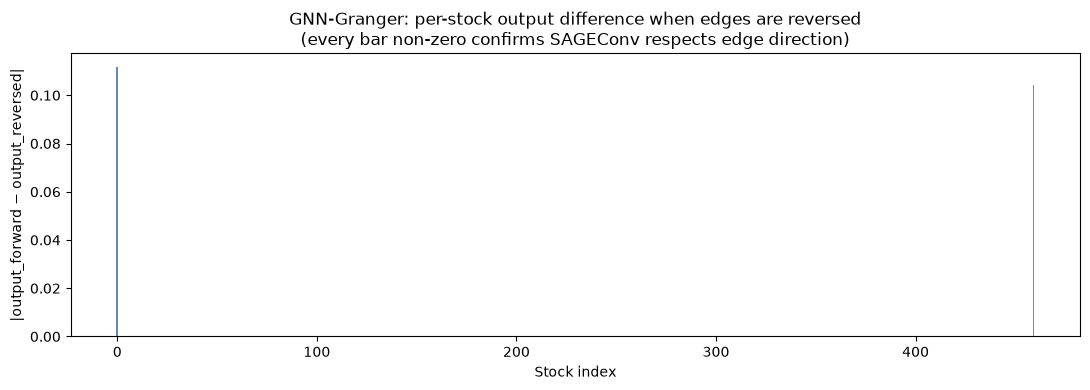

In [14]:
granger_reversed = granger_edge_index[[1, 0]]

gnn_test.eval()
with torch.no_grad():
    out_forward  = gnn_test(features_t, granger_edge_index.to(device))
    out_reversed = gnn_test(features_t, granger_reversed.to(device))

diff = (out_forward - out_reversed).abs().cpu().numpy()
if torch.allclose(out_forward, out_reversed):
    # Keep only edges whose reverse is absent from the original graph.
    edge_pairs = {
        (src, dst)
        for src, dst in granger_edge_index.detach().cpu().t().tolist()
    }
    one_way_edges = [
        (src, dst) for src, dst in edge_pairs
        if (dst, src) not in edge_pairs
    ]
    if not one_way_edges:
        # The saved graph is reciprocal; retain one orientation per pair
        # to create a directed probe from its existing edges.
        one_way_edges = sorted(
            (src, dst) for src, dst in edge_pairs if src < dst
        )

    if one_way_edges:
        probe_source = "Granger graph"
    else:
        if features_t.shape[0] < 2:
            raise ValueError("At least two stocks are required for a directionality probe.")
        one_way_edges = [(0, features_t.shape[0] - 1)]
        probe_source = "synthetic fallback"

    print(f"Directionality probe edges: {probe_source}")
    if probe_source == "synthetic fallback":
        print("WARNING: Granger graph has no non-self edges; check graph construction "
              "and apply the configured multiple-testing fallback.")

    probe_edge_index = torch.tensor(
        one_way_edges, dtype=torch.long, device=device
    ).t().contiguous()

    with torch.no_grad():
        out_forward = gnn_test(features_t, probe_edge_index)
        out_reversed = gnn_test(features_t, probe_edge_index[[1, 0]])

    diff = (out_forward - out_reversed).abs().cpu().numpy()

assert not np.allclose(out_forward.cpu().numpy(), out_reversed.cpu().numpy(),
                       atol=1e-8, rtol=1e-6), \
    "Directionality check failed even on one-way edges"

print(f"Directionality confirmed.")
print(f"  Max  |diff|: {diff.max():.4f}")
print(f"  Mean |diff|: {diff.mean():.4f}")
print(f"  Stocks with diff > 0: {(diff > 0).sum()} / {len(diff)}")

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(range(n_stocks), diff, width=0.8, color="#4C72B0", edgecolor="none", alpha=0.85)
ax.set_xlabel("Stock index")
ax.set_ylabel("|output_forward − output_reversed|")
ax.set_title(
    "GNN-Granger: per-stock output difference when edges are reversed\n"
    "(every bar non-zero confirms SAGEConv respects edge direction)"
)
plt.tight_layout()
plt.show()

### Plot 5: GNN output vs actual RV (random initialization)

At random init the GNN predictions carry no signal; Pearson r should be near zero.
HAR predictions (red ×) are shown on the same axes as a reference: HAR r should be
strongly positive, making the contrast clear.

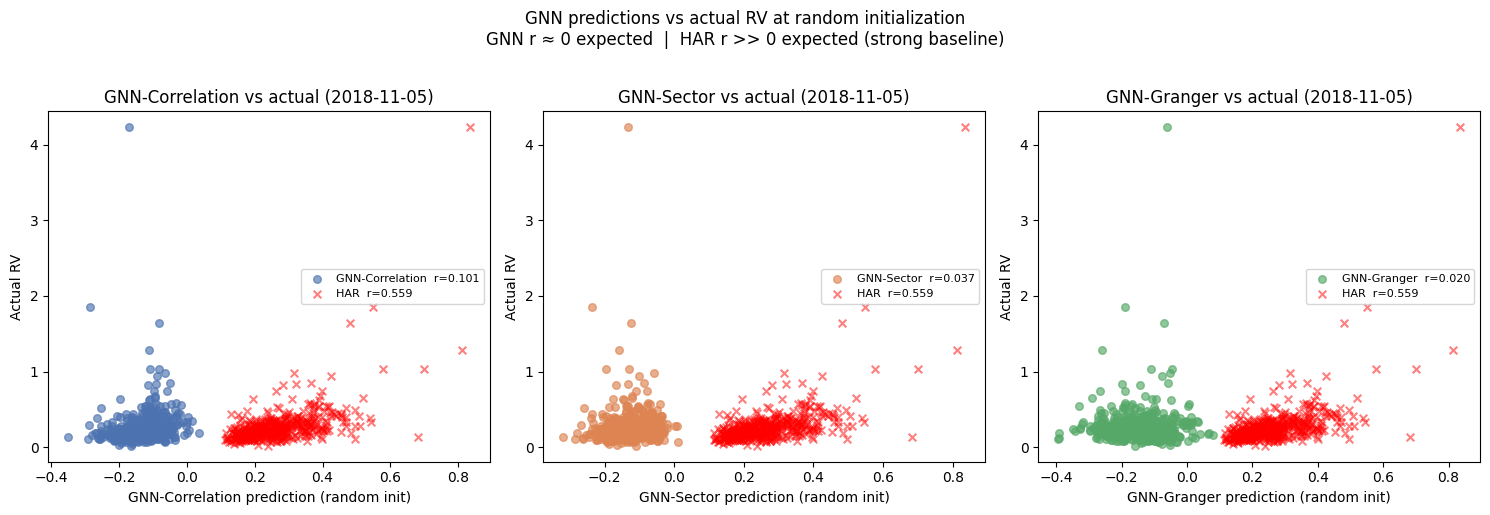

In [ ]:
# HAR predictions for the sample week (single-week inference)
X_sample = {
    t: np.array([[rv_1w.loc[sample_week, t],
                  rv_4w.loc[sample_week, t],
                  rv_13w.loc[sample_week, t]]])
    for t in tickers
}
har_sample_preds = har.predict(X_sample)
har_sample_arr   = np.array([har_sample_preds[t][0] for t in tickers])
har_r            = np.corrcoef(har_sample_arr, actual_rv)[0, 1]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, out, color) in zip(axes, graph_data):
    preds = out.cpu().numpy()
    r     = np.corrcoef(preds, actual_rv)[0, 1]
    ax.scatter(preds, actual_rv, alpha=0.65, s=30, color=color,
               label=f"GNN-{name}  r={r:.3f}")
    ax.scatter(har_sample_arr, actual_rv, alpha=0.5, s=30, marker="x",
               color="red", label=f"HAR  r={har_r:.3f}")
    ax.set_xlabel(f"GNN-{name} prediction (random init)")
    ax.set_ylabel("Actual RV")
    ax.set_title(f"GNN-{name} vs actual ({sample_week.date()})")
    ax.legend(fontsize=8)

plt.suptitle(
    "GNN predictions vs actual RV at random initialization\n"
    "GNN r ≈ 0 expected  |  HAR r >> 0 expected (strong baseline)",
    y=1.02
)
plt.tight_layout()
plt.show()

### GNN-Correlation — Threshold Ablation

Train GNN-Correlation with θ ∈ {0.3, 0.5, 0.7}. Each run uses identical architecture,
seeds, and hyperparameters. The threshold with the lowest validation MSE is selected
and its checkpoint is copied to `gnn_corr_best.pt`.

In [ ]:
_ckpt_path    = Path(config.CHECKPOINTS_DIR) / "gnn_corr_best.pt"
_ablation_path = Path(config.DATA_RESULTS_DIR) / "corr_threshold_ablation.json"

if _ckpt_path.exists() and _ablation_path.exists():
    print("gnn_corr_best.pt and corr_threshold_ablation.json found — skipping training.")
    _abl_data = json.load(open(_ablation_path))
    ablation  = {float(k): v for k, v in _abl_data["val_mse_by_threshold"].items()}
    print(f"Best θ={_abl_data['best_threshold']}  val MSE={_abl_data['best_val_mse']:.6f}")
else:
    # Load precomputed graphs for training and validation (both needed during training).
    corr_graphs = {
        th: {**load_corr_graphs(th, "train"), **load_corr_graphs(th, "val")}
        for th in config.CORR_ABLATION_THRESHOLDS
    }
    ablation = train_gnn_corr_ablation(
        features=features_3d,
        target=target_arr,
        week_index=target.index,
        corr_graphs=corr_graphs,
        splits=splits,
        device=device,
    )

gnn_corr_best.pt and corr_threshold_ablation.json found — skipping training.
Best θ=0.3  val MSE=0.019778


In [ ]:
ablation_data = json.load(open(Path(config.DATA_RESULTS_DIR) / "corr_threshold_ablation.json"))

print(f"{'θ':>6}  {'Val MSE':>12}  {'Selected':>8}")
print("-" * 32)
for theta_str, mse in ablation_data["val_mse_by_threshold"].items():
    marker = "<-- best" if float(theta_str) == ablation_data["best_threshold"] else ""
    print(f"{float(theta_str):>6.1f}  {mse:>12.6f}  {marker}")
print()
print(f"Best threshold : θ = {ablation_data['best_threshold']}")
print(f"Best val MSE   : {ablation_data['best_val_mse']:.6f}")
print(f"Checkpoint     : gnn_corr_best.pt")

     θ       Val MSE  Selected
--------------------------------
   0.3      0.019778  <-- best
   0.5      0.020404  
   0.7      0.020848  

Best threshold : θ = 0.3
Best val MSE   : 0.019778
Checkpoint     : gnn_corr_best.pt


### GNN-Sector Training

Train GNN-Sector using annual point-in-time GICS sector graphs. All stocks sharing the same sector at the start of the calendar year are connected. The graph updates once per year rather than weekly, so training is faster than GNN-Correlation. Architecture and hyperparameters are identical to Task 4.4.

In [ ]:
from src.train import train_gnn_sector, predict_gnn_val
from src.graphs import build_all_sector_graphs

# Pre-build sector graphs for all years in the dataset
# sector_history is already loaded in the setup cell above
sector_graphs_dict = build_all_sector_graphs(
    tickers=tickers,
    sector_history=sector_history,
    years=range(2015, 2026),
)

print(f"\nBuilt sector graphs for {len(sector_graphs_dict)} years:")
for year in sorted(sector_graphs_dict):
    print(f"  {year}: {sector_graphs_dict[year].shape[1]:,} edges")

Saved 269890 total edges across 11 years to <project-root>\data\graphs\sector_edges_by_year.parquet

Built sector graphs for 11 years:
  2015: 28,386 edges
  2016: 28,386 edges
  2017: 24,442 edges
  2018: 24,442 edges
  2019: 23,462 edges
  2020: 23,462 edges
  2021: 23,462 edges
  2022: 23,462 edges
  2023: 23,462 edges
  2024: 23,462 edges
  2025: 23,462 edges


In [ ]:
_ckpt_path = Path(config.CHECKPOINTS_DIR) / "gnn_sector_best.pt"

if _ckpt_path.exists():
    print("gnn_sector_best.pt found — skipping training.")
    _sector_state = torch.load(_ckpt_path, map_location=device, weights_only=True)
    _sector_hidden = next(v.shape[0] for k, v in _sector_state.items() if "lin_l.weight" in k)
    gnn_sector = GNNModel(in_channels=n_feats, hidden_dim=_sector_hidden).to(device)
    gnn_sector.load_state_dict(_sector_state)
    _loss_data      = json.load(open(Path(config.DATA_RESULTS_DIR) / "gnn_sector_val_loss.json"))
    sector_val_loss = _loss_data["val_loss"]
    print(f"Best val MSE: {_loss_data['best_val_loss']:.6f}")
else:
    gnn_sector, sector_val_loss = train_gnn_sector(
        features=features_3d,
        target=target_arr,
        week_index=target.index,
        sector_graphs=sector_graphs_dict,
        splits=splits,
        device=device,
    )
    print(f"\nTraining complete. Best checkpoint: gnn_sector_best.pt")

gnn_sector_best.pt found — skipping training.
Best val MSE: 0.022894


In [ ]:
# Val MSE comparison: GNN-Sector vs GNN-Correlation
sector_loss_data = json.load(open(Path(config.DATA_RESULTS_DIR) / "gnn_sector_val_loss.json"))
corr_data        = json.load(open(Path(config.DATA_RESULTS_DIR) / "corr_threshold_ablation.json"))

sector_mse = sector_loss_data["best_val_loss"]
corr_mse   = corr_data["best_val_mse"]
best_theta = corr_data["best_threshold"]
diff_pct   = (sector_mse - corr_mse) / corr_mse * 100

print(f"{'Model':<28}  {'Best Val MSE':>12}  {'vs GNN-Corr':>12}")
print("-" * 56)
print(f"{'GNN-Correlation (θ=' + str(best_theta) + ')':<28}  {corr_mse:>12.6f}  {'(reference)':>12}")
print(f"{'GNN-Sector':<28}  {sector_mse:>12.6f}  {diff_pct:>+11.2f}%")
print()
winner = "GNN-Sector" if sector_mse < corr_mse else f"GNN-Correlation (θ={best_theta})"
print(f"Lower val MSE: {winner}")

Model                         Best Val MSE   vs GNN-Corr
--------------------------------------------------------
GNN-Correlation (θ=0.3)           0.019778   (reference)
GNN-Sector                        0.022894       +15.75%

Lower val MSE: GNN-Correlation (θ=0.3)


In [ ]:
# Load best sector checkpoint and generate val-set predictions for sector breakdown
ckpt_dir = Path(config.CHECKPOINTS_DIR)
_sector_state = torch.load(ckpt_dir / "gnn_sector_best.pt", map_location=device, weights_only=True)
_sector_hidden = next(v.shape[0] for k, v in _sector_state.items() if "lin_l.weight" in k)
model_sector_eval = GNNModel(in_channels=n_feats, hidden_dim=_sector_hidden).to(device)
model_sector_eval.load_state_dict(_sector_state)

sector_edge_fn = lambda week: sector_graphs_dict[week.year]

val_preds_sector = predict_gnn_val(
    model=model_sector_eval,
    features=features_3d,
    target=target_arr,
    week_index=target.index,
    edge_index_fn=sector_edge_fn,
    splits=splits,
    tickers=tickers,
    device=device,
)
val_target_sector = pd.DataFrame(
    target_arr, index=target.index, columns=tickers
).loc[val_preds_sector.index]

print(f"Val predictions: {val_preds_sector.shape}  (weeks x stocks)")
print(f"Val targets:     {val_target_sector.shape}")

Val predictions: (52, 465)  (weeks x stocks)
Val targets:     (52, 465)


<project-root>\src\models.py:289: UserWarning: GNNModel.forward: input features contain NaN values. Imputing with 0 (z-score mean). Expected during warm-up weeks.
  warnings.warn(


In [ ]:
# Per-sector val MSE breakdown for GNN-Sector
# Uses 2023 point-in-time sector assignments (val year)
sector_map_val = {t: sector_history.get(t, {}).get("2023") for t in tickers}
all_sectors    = sorted(s for s in set(sector_map_val.values()) if s is not None)

sector_mse_rows = []
for sector in all_sectors:
    cols = [t for t in tickers if sector_map_val.get(t) == sector]
    if not cols:
        continue
    preds_s   = val_preds_sector[cols].values
    targets_s = val_target_sector[cols].values
    sector_mse_rows.append((sector, len(cols), float(np.mean((preds_s - targets_s) ** 2))))

sector_mse_rows.sort(key=lambda x: x[2], reverse=True)
print(f"GNN-Sector val MSE by GICS sector (2023, highest to lowest):")
print(f"{'Sector':<35}  {'Stocks':>6}  {'Val MSE':>10}")
print("-" * 57)
for sec, n, mse in sector_mse_rows:
    print(f"{sec:<35}  {n:>6}  {mse:>10.6f}")

GNN-Sector val MSE by GICS sector (2023, highest to lowest):
Sector                               Stocks     Val MSE
---------------------------------------------------------
Communication Services                   20    0.044430
Information Technology                   72    0.032336
Unknown                                   1    0.029912
Consumer Discretionary                   51    0.023113
Materials                                18    0.022211
Industrials                              67    0.022201
Financials                               68    0.022189
Health Care                              55    0.021395
Energy                                   21    0.017922
Consumer Staples                         34    0.016906
Real Estate                              29    0.014219
Utilities                                29    0.009785


### GNN-Granger Training

Train GNN-Granger using the static directed Granger causality graph computed in Task 3.3.
The edge index is fixed for all time steps. `build_granger_graph()` reads the saved
p-value matrix and applies multiple-comparison correction without re-running any tests.
If the checkpoint exists, training is skipped and the saved model is loaded directly.

In [ ]:
from src.train import train_gnn_granger
from src.graphs import build_granger_graph

# Load static Granger graph from saved parquet (no recomputation of p-values)
granger_ei, correction_used = build_granger_graph(tickers)
print(f"Granger edges: {granger_ei.shape[1]:,}  |  Correction: {correction_used}")

_ckpt_path = Path(config.CHECKPOINTS_DIR) / "gnn_granger_best.pt"

if _ckpt_path.exists():
    print("gnn_granger_best.pt found — skipping training.")
    _granger_state = torch.load(_ckpt_path, map_location=device, weights_only=True)
    _granger_hidden = next(v.shape[0] for k, v in _granger_state.items() if "lin_l.weight" in k)
    gnn_granger = GNNModel(in_channels=n_feats, hidden_dim=_granger_hidden).to(device)
    gnn_granger.load_state_dict(_granger_state)
    _loss_data = json.load(
        open(Path(config.DATA_RESULTS_DIR) / "gnn_granger_val_loss.json")
    )
    granger_val_loss = _loss_data["val_loss"]
    print(f"Best val MSE: {_loss_data['best_val_loss']:.6f}")
else:
    gnn_granger, granger_val_loss = train_gnn_granger(
        features=features_3d,
        target=target_arr,
        week_index=target.index,
        granger_edge_index=granger_ei,
        splits=splits,
        device=device,
    )
    print(f"\nTraining complete. Checkpoint: gnn_granger_best.pt")

Correction: bonferroni  |  Edges: 13,886 / 215,760 pairs
Saved 13,886 directed edges -> <project-root>\data\graphs\granger_edges.parquet
Granger edges: 13,886  |  Correction: bonferroni
gnn_granger_best.pt found — skipping training.
Best val MSE: 0.022615


In [ ]:
granger_loss_data = json.load(
    open(Path(config.DATA_RESULTS_DIR) / "gnn_granger_val_loss.json")
)
granger_mse = granger_loss_data["best_val_loss"]

print(f"Correction method : {correction_used}")
print(f"Granger edges     : {granger_ei.shape[1]:,}")
print()
print(f"{'Model':<30}  {'Best Val MSE':>12}")
print("-" * 46)
print(f"{'GNN-Correlation (θ=' + str(corr_data['best_threshold']) + ')':<30}  {corr_mse:>12.6f}")
print(f"{'GNN-Sector':<30}  {sector_mse:>12.6f}")
print(f"{'GNN-Granger':<30}  {granger_mse:>12.6f}")
print()
best_gnn = min(
    [("GNN-Correlation", corr_mse), ("GNN-Sector", sector_mse), ("GNN-Granger", granger_mse)],
    key=lambda x: x[1],
)
print(f"Best GNN variant: {best_gnn[0]}  val MSE={best_gnn[1]:.6f}")

Correction method : bonferroni
Granger edges     : 13,886

Model                           Best Val MSE
----------------------------------------------
GNN-Correlation (θ=0.3)             0.019778
GNN-Sector                          0.022894
GNN-Granger                         0.022615

Best GNN variant: GNN-Correlation  val MSE=0.019778


## Experiment registry reference

Current training and evaluation artifacts should be registered before downstream comparison.

In [ ]:
# REGISTRY_REFERENCE_CELL
from pathlib import Path
import pandas as pd
from IPython.display import display

registry_path = Path('../data/results/experiment_registry.csv')
registry = pd.read_csv(registry_path)
display(registry[['experiment_id', 'model_name', 'feature_version', 'graph_version', 'checkpoint_path']])
print(f'Registry path: {registry_path.as_posix()}')


,experiment_id,model_name,feature_version,graph_version,checkpoint_path
0,baseline_har_per_stock,HAR per-stock,har_realized_volatility_lags_v1,none,NaN
1,baseline_har_pooled,HAR pooled,har_realized_volatility_lags_v1,none,NaN
2,baseline_lstm,LSTM,stock_features_v1,none,data/results/checkpoints/lstm_best.pt
3,baseline_gnn_correlation,GNN-Correlation,stock_features_v1,correlation_threshold_0.3_lookback_252,data/results/checkpoints/gnn_corr_hparam_best.pt
4,baseline_gnn_sector,GNN-Sector,stock_features_v1,sector_canonical_gics_labels_v1,data/results/checkpoints/gnn_sector_best.pt
5,baseline_gnn_granger,GNN-Granger,stock_features_v1,granger_lag_5_bonferroni,data/results/checkpoints/gnn_granger_best.pt
6,baseline_gnn_ensemble,GNN-Ensemble,stock_features_v1,correlation+sector+granger_v1,NaN
7,rankloss_gnn_correlation,Rank-loss GNN-Correlation,stock_features_v1,correlation_threshold_0.3_lookback_252,data/results/checkpoints/gnn_corr_rankloss_bes...
8,rankloss_gnn_sector,Rank-loss GNN-Sector,stock_features_v1,sector_canonical_gics_labels_v1,data/results/checkpoints/gnn_sector_rankloss_b...
9,rankloss_gnn_granger,Rank-loss GNN-Granger,stock_features_v1,granger_lag_5_bonferroni,data/results/checkpoints/gnn_granger_rankloss_...


Registry path: ../data/results/experiment_registry.csv


### Validation Summary and Go/No-Go Checkpoint

All six models ranked by validation MSE (2023, dev universe).
The gate: at least one GNN variant must beat HAR per-stock on val MSE before proceeding to test evaluation.

In [ ]:
from src.evaluate import compile_validation_summary

ranked_table, go_nogo = compile_validation_summary(
    features=features_3d,
    target=target_arr,
    week_index=target.index,
    splits=splits,
    tickers=tickers,
    sector_graphs=sector_graphs_dict,
    granger_edge_index=granger_edge_index,
    device=device,
)

print(f"Decision: {go_nogo}")
print(ranked_table.to_string(float_format=lambda x: f"{x:.6f}"))
print(f"\nSaved: {Path(config.DATA_RESULTS_DIR) / 'validation_summary.json'}")

<project-root>\src\models.py:350: UserWarning: GNNModelV2.forward: input features contain NaN values. Imputing with 0 (z-score mean). Expected during warm-up weeks.
  warnings.warn(


<project-root>\src\models.py:289: UserWarning: GNNModel.forward: input features contain NaN values. Imputing with 0 (z-score mean). Expected during warm-up weeks.
  warnings.warn(


Decision: GO
                         rank      mse      mae       r2
model                                                   
GNN-Correlation (θ=0.3)     1 0.019646 0.093724 0.171245
LSTM                        2 0.020786 0.098701 0.119233
HAR per-stock               3 0.021841 0.101601 0.078653
HAR pooled                  4 0.021951 0.101225 0.074002
GNN-Granger                 5 0.022615 0.109183 0.045988
GNN-Sector                  6 0.022894 0.112171 0.034230

Saved: <project-root>\data\results\validation_summary.json


## Oversmoothing diagnostics

<!-- STEP5_OVERSMOOTHING_DIAGNOSTICS -->

Layer-dispersion audit


,model,experiment_id,graph_type,week_label,week,layer,num_edges,mean_pairwise_embedding_distance,mean_absolute_deviation,final_to_layer1_distance_ratio
0,GNN-Correlation,baseline_gnn_correlation,correlation,calm_2017,2017-06-26,layer_1,39190,4.468418,0.133520,0.129854
1,GNN-Correlation,baseline_gnn_correlation,correlation,calm_2017,2017-06-26,layer_2,39190,3.058154,0.036826,0.129854
2,GNN-Correlation,baseline_gnn_correlation,correlation,calm_2017,2017-06-26,layer_3,39190,0.580244,0.007605,0.129854
3,GNN-Correlation,baseline_gnn_correlation,correlation,covid_2020,2020-03-09,layer_1,197420,2.505151,0.057013,0.269492
4,GNN-Correlation,baseline_gnn_correlation,correlation,covid_2020,2020-03-09,layer_2,197420,1.243011,0.016072,0.269492
...,...,...,...,...,...,...,...,...,...,...
65,Rank-loss GNN-Sector,rankloss_gnn_sector,sector,representative_2023_val,2023-06-26,layer_2,23462,3.356238,0.148258,1.007694
66,Rank-loss GNN-Sector,rankloss_gnn_sector,sector,representative_2024_test,2024-06-24,layer_1,23462,3.312388,0.150089,1.002921
67,Rank-loss GNN-Sector,rankloss_gnn_sector,sector,representative_2024_test,2024-06-24,layer_2,23462,3.322063,0.148233,1.002921
68,Rank-loss GNN-Sector,rankloss_gnn_sector,sector,representative_2025_test,2025-06-23,layer_1,23462,3.297246,0.150509,0.980451


Final-layer dispersion ratios


week_label,calm_2017,covid_2020,representative_2023_val,representative_2024_test,representative_2025_test
model,,,,,
GNN-Correlation,0.1299,0.2695,0.1704,0.1434,0.1580
GNN-Granger,0.3237,0.4260,0.3397,0.3434,0.3324
GNN-Sector,0.3266,0.3567,0.3210,0.3228,0.3096
Rank-loss GNN-Correlation,0.4495,0.4929,0.4005,0.4266,0.3928
Rank-loss GNN-Granger,0.9597,0.9403,0.9191,0.8935,0.9127
Rank-loss GNN-Sector,1.0849,1.2379,1.0077,1.0029,0.9805


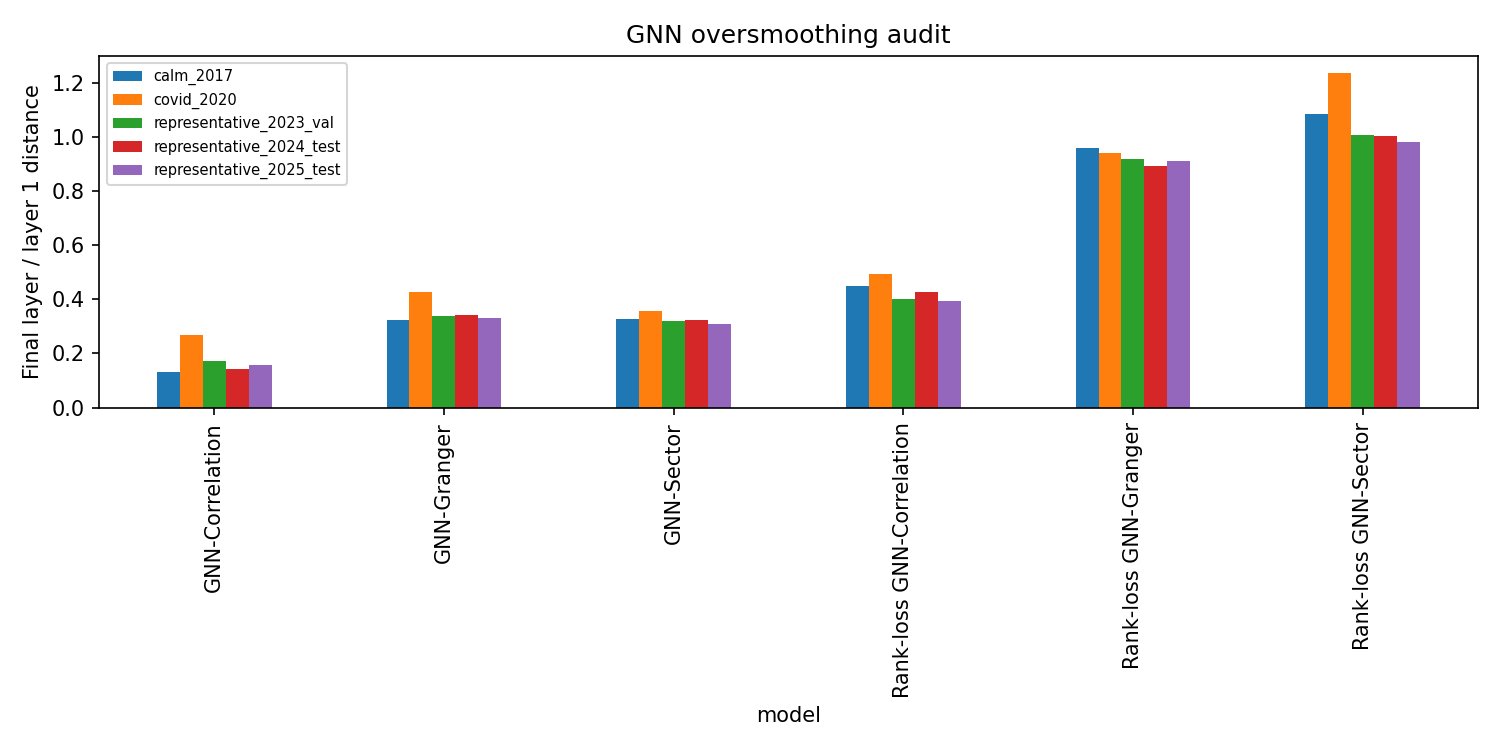

In [ ]:
# STEP5_OVERSMOOTHING_DIAGNOSTICS_TABLE
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

results_dir = Path('../data/results')
figures_dir = results_dir / 'figures'
oversmoothing = pd.read_csv(results_dir / 'oversmoothing_audit.csv', parse_dates=['week'])

print('Layer-dispersion audit')
display(oversmoothing.sort_values(['model', 'week', 'layer']))

print('Final-layer dispersion ratios')
final_layers = (
    oversmoothing.sort_values('layer')
    .groupby(['model', 'week_label'], as_index=False)
    .tail(1)
)
display(
    final_layers.pivot_table(
        index='model',
        columns='week_label',
        values='final_to_layer1_distance_ratio',
    ).round(4)
)
display(Image(filename=str(figures_dir / 'oversmoothing_audit.png')))